# Phase 3: Measure the Lesions

Turn masks into answers: **how many** lesions, **where** they are, **how big** they are and **what shape** they have.

The same measuring code is used for:
- the **ground-truth** masks (hand-drawn), to learn what benign and malignant lesions look like, and as the reference to check the models against;
- the **predicted** masks of any model (`unet`, `unet_multitask` or later `yolo`), chosen with the `MODEL` setting.

**Input:**
- `data/manifest.csv` and the ground-truth masks in `data/`
- `outputs/<MODEL>/masks/`: predicted test masks (created by `03_model_unet` or `05_model_yolo`)
- `outputs/<MODEL>/test_predictions.csv`: predicted class, if the model has one

**Output:**

| File | What it contains |
| ---- | ---------------- |
| `outputs/ground_truth/measurements.csv` | Every true lesion in every image (all splits) |
| `outputs/ground_truth/shape_by_class.png` | Benign vs malignant size and shape |
| `outputs/<MODEL>/measurements.csv` | Every predicted lesion in every test image |
| `outputs/<MODEL>/lesion_matches.csv` | Each true test lesion matched with its predicted lesion, with the errors |
| `outputs/<MODEL>/measurement_metrics.json` | How accurate the counts, sizes, locations and shapes are |
| `outputs/<MODEL>/size_comparison.png` | Predicted vs true lesion size |
| `outputs/<MODEL>/overlays/` | Every test image with its lesions outlined and numbered (for the app) |

> All sizes are in **pixels** because the images don't record the scanner's mm per pixel. Locations are positions **in the image**, not in the breast.

## 1. Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from skimage.measure import label, regionprops, perimeter

## 2. Settings

In [2]:
DATA_DIR = Path('data')

MODEL = 'unet_multitask'      # whose predicted masks to measure: 'unet', 'unet_multitask' or 'yolo'

MODEL_DIR = Path('outputs') / MODEL
GROUND_TRUTH_DIR = Path('outputs/ground_truth')
OVERLAY_DIR = MODEL_DIR / 'overlays'
GROUND_TRUTH_DIR.mkdir(parents=True, exist_ok=True)
OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

MIN_LESION_PIXELS = 50     # same as the other notebooks: smaller regions are noise
MATCH_IOU = 0.5            # a predicted lesion 'finds' a true lesion if they overlap at least this much (IoU)

# Simple shape rules, inspired by BI-RADS (approximate, not a clinical rule)
IRREGULAR_SOLIDITY = 0.90  # below this the outline has big dents       -> irregular
IRREGULAR_ROUGHNESS = 1.15 # above this the outline is wiggly or spiky  -> irregular
ROUND_AXIS_RATIO = 0.80    # short axis / long axis above this          -> round, otherwise oval

manifest = pd.read_csv(DATA_DIR / 'manifest.csv')
test_df = manifest[manifest['split'] == 'test'].reset_index(drop=True)
print(f'Measuring masks from: {MODEL_DIR}  |  {len(test_df)} test images')

Measuring masks from: outputs/unet_multitask  |  104 test images


## 3. The measuring functions

1. **Split the mask into lesions:** separate white regions (connected components) are separate lesions. Tiny specks are dropped, and lesions are numbered from largest to smallest.
2. **Measure each lesion:**

| Group | Measurement | How it's calculated |
| ----- | ----------- | ------------------- |
| Size | `area_px`, `area_pct` | Pixels inside the lesion, and as % of the whole image |
| | `box_width_px`, `box_height_px` | Size of the box around the lesion |
| | `longest_diameter_px` | Longest straight line across the lesion (like a radiologist's caliper) |
| | `equivalent_diameter_px` | Diameter of a circle with the same area |
| Location | `centre_x`, `centre_y` | Centre of the lesion in pixels (and `_frac`: 0 to 1 of width / height) |
| | `box_left` ... `box_bottom` | Box corners in pixels |
| | `depth_px`, `depth_frac` | Distance from the top edge (the skin) to the top of the lesion |
| | `horizontal_zone`, `depth_zone` | Left / centre / right and shallow / mid / deep third of the image |
| Shape | `circularity` | 4π × area / perimeter²: 1 = perfect circle, lower = less round |
| | `solidity` | Area / area of its convex hull (the outline with all dents filled in): 1 = no dents |
| | `axis_ratio` | Short axis / long axis: 1 = round, lower = elongated |
| | `edge_roughness` | Outline length / convex outline length: 1 = smooth, higher = wiggly or spiky |
| | `orientation` | Wider than tall, or taller than wide (taller than wide is a warning sign) |
| | `shape` | round / oval / irregular, from the rules in Settings |

In [3]:
def load_true_mask(mask_paths):
    """Merge an image's ground-truth masks into one True/False array."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return np.any(masks, axis=0)


def load_pred_mask(image_path):
    """Load a model's predicted mask for an image (saved with the same folder and file name)."""
    return np.array(Image.open(MODEL_DIR / 'masks' / image_path).convert('L')) > 127


def find_lesions(mask):
    """Split a True/False mask into separate lesions, largest first.
    Returns a list of (region, lesion_mask): the skimage region and a True/False mask of just that lesion."""
    labelled = label(mask, connectivity=2)                     # give each separate region its own number
    regions = [r for r in regionprops(labelled) if r.area >= MIN_LESION_PIXELS]
    regions.sort(key=lambda r: r.area, reverse=True)
    return [(r, labelled == r.label) for r in regions]


def zone(fraction, names):
    """Which third of the image a 0..1 position falls in, e.g. 0.1 -> names[0]."""
    return names[min(int(fraction * 3), 2)]


def describe_shape(solidity, roughness, axis_ratio):
    """round / oval / irregular, using the simple rules from Settings."""
    if solidity < IRREGULAR_SOLIDITY or roughness > IRREGULAR_ROUGHNESS:
        return 'irregular'
    return 'round' if axis_ratio >= ROUND_AXIS_RATIO else 'oval'


def measure_lesion(region, width, height):
    """Size, location and shape of one lesion."""
    top, left, bottom, right = region.bbox
    centre_y, centre_x = region.centroid
    box_width, box_height = right - left, bottom - top

    convex_perimeter = perimeter(region.image_convex)
    roughness = region.perimeter / convex_perimeter if convex_perimeter else 1.0
    axis_ratio = region.axis_minor_length / region.axis_major_length if region.axis_major_length else 1.0
    circularity = min(4 * np.pi * region.area / region.perimeter ** 2, 1.0) if region.perimeter else 1.0

    return {
        # Size
        'area_px': int(region.area),
        'area_pct': round(region.area / (width * height) * 100, 3),
        'box_width_px': int(box_width),
        'box_height_px': int(box_height),
        'longest_diameter_px': round(float(region.feret_diameter_max), 1),
        'equivalent_diameter_px': round(float(region.equivalent_diameter_area), 1),
        # Location
        'centre_x': round(float(centre_x), 1),
        'centre_y': round(float(centre_y), 1),
        'centre_x_frac': round(centre_x / width, 3),
        'centre_y_frac': round(centre_y / height, 3),
        'box_left': int(left), 'box_top': int(top), 'box_right': int(right), 'box_bottom': int(bottom),
        'depth_px': int(top),
        'depth_frac': round(top / height, 3),
        'horizontal_zone': zone(centre_x / width, ['left', 'centre', 'right']),
        'depth_zone': zone(centre_y / height, ['shallow', 'mid', 'deep']),
        # Shape
        'circularity': round(float(circularity), 3),
        'solidity': round(float(region.solidity), 3),
        'axis_ratio': round(float(axis_ratio), 3),
        'edge_roughness': round(float(roughness), 3),
        'orientation': 'taller than wide' if box_height > box_width else 'wider than tall',
        'shape': describe_shape(region.solidity, roughness, axis_ratio),
    }


def measure_mask(mask):
    """Measure every lesion in a mask. Returns one dict per lesion, numbered 1, 2, ... (largest first)."""
    height, width = mask.shape
    return [{'lesion': number, **measure_lesion(region, width, height)}
            for number, (region, _) in enumerate(find_lesions(mask), start=1)]

In [4]:
# Try it on one image with two lesions
example = manifest[manifest['n_lesions'] >= 2].iloc[0]
print(example['image_path'])
pd.DataFrame(measure_mask(load_true_mask(example['mask_paths'])))

benign/benign (100).png


,lesion,area_px,area_pct,box_width_px,box_height_px,longest_diameter_px,equivalent_diameter_px,centre_x,centre_y,centre_x_frac,...,depth_px,depth_frac,horizontal_zone,depth_zone,circularity,solidity,axis_ratio,edge_roughness,orientation,shape
0,1,7090,4.641,101,96,121.3,95.0,253.1,177.5,0.784,...,126,0.266,right,mid,0.814,0.985,0.654,1.014,wider than tall,oval
1,2,2921,1.912,71,51,73.4,61.0,62.3,132.0,0.193,...,107,0.226,left,shallow,0.870,0.979,0.712,1.006,wider than tall,oval


## 4. Ground truth: what do benign and malignant lesions look like?

We measure every hand-drawn lesion in **all** images (train, val and test) to see whether size and shape differ between the classes. If they do, the measurements are useful on their own, not just as a description.

In [5]:
rows = []
for row in manifest[manifest['label'] != 'normal'].itertuples():
    for lesion in measure_mask(load_true_mask(row.mask_paths)):
        rows.append({'image_path': row.image_path, 'label': row.label, 'split': row.split, **lesion})

true_lesions = pd.DataFrame(rows)
true_lesions.to_csv(GROUND_TRUTH_DIR / 'measurements.csv', index=False)
print(f'{len(true_lesions)} true lesions measured')

true_lesions.groupby('label')[['area_pct', 'longest_diameter_px', 'circularity', 'solidity',
                               'axis_ratio', 'edge_roughness']].median().round(3)

595 true lesions measured


,area_pct,longest_diameter_px,circularity,solidity,axis_ratio,edge_roughness
label,,,,,,
benign,3.159,160.70,0.782,0.981,0.575,1.007
malignant,12.151,301.05,0.560,0.884,0.646,1.092


In [6]:
# % of lesions in each class that are irregular / taller than wide
pd.DataFrame({
    'irregular_%': true_lesions.groupby('label')['shape'].apply(lambda s: (s == 'irregular').mean() * 100),
    'taller_than_wide_%': true_lesions.groupby('label')['orientation'].apply(lambda s: (s == 'taller than wide').mean() * 100),
}).round(1)

,irregular_%,taller_than_wide_%
label,,
benign,1.3,1.5
malignant,58.3,11.3


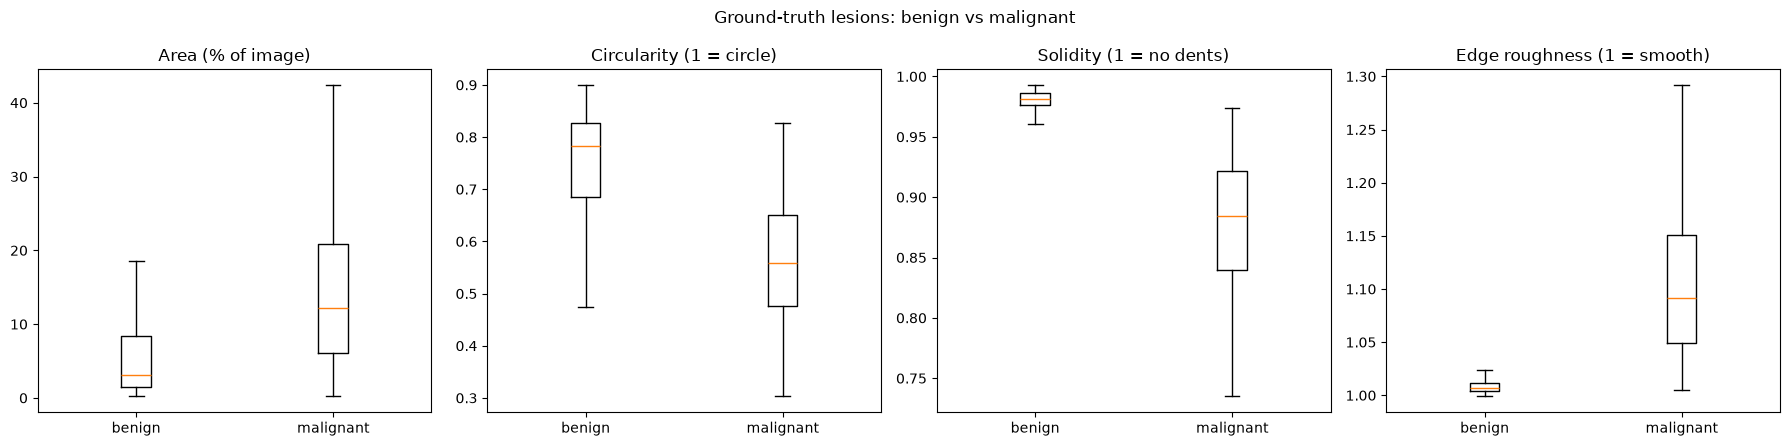

In [7]:
features = [('area_pct', 'Area (% of image)'), ('circularity', 'Circularity (1 = circle)'),
            ('solidity', 'Solidity (1 = no dents)'), ('edge_roughness', 'Edge roughness (1 = smooth)')]

fig, axes = plt.subplots(1, len(features), figsize=(18, 4.5))
for ax, (column, title) in zip(axes, features):
    data = [true_lesions.loc[true_lesions['label'] == c, column] for c in ['benign', 'malignant']]
    ax.boxplot(data, tick_labels=['benign', 'malignant'], showfliers=False)
    ax.set_title(title)

plt.suptitle('Ground-truth lesions: benign vs malignant')
plt.tight_layout()
plt.savefig(GROUND_TRUTH_DIR / 'shape_by_class.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Measure the model's predicted masks (test images)

In [8]:
rows = []
for row in test_df.itertuples():
    for lesion in measure_mask(load_pred_mask(row.image_path)):
        rows.append({'image_path': row.image_path, 'label': row.label, **lesion})

pred_lesions = pd.DataFrame(rows)
pred_lesions.to_csv(MODEL_DIR / 'measurements.csv', index=False)
print(f'{len(pred_lesions)} predicted lesions in {len(test_df)} test images')
pred_lesions.head()

103 predicted lesions in 104 test images


,image_path,label,lesion,area_px,area_pct,box_width_px,box_height_px,longest_diameter_px,equivalent_diameter_px,centre_x,...,depth_px,depth_frac,horizontal_zone,depth_zone,circularity,solidity,axis_ratio,edge_roughness,orientation,shape
0,normal/normal (108).png,normal,1,2817,0.621,84,54,87.4,59.9,442.8,...,174,0.295,centre,mid,0.532,0.893,0.570,1.158,wider than tall,irregular
1,normal/normal (58).png,normal,1,4724,1.751,112,54,115.2,77.6,311.2,...,134,0.275,centre,shallow,0.620,0.955,0.473,1.067,wider than tall,oval
2,normal/normal (73).png,normal,1,772,0.320,50,26,51.2,31.4,156.0,...,36,0.076,left,shallow,0.517,0.860,0.432,1.100,wider than tall,irregular
3,normal/normal (73).png,normal,2,72,0.030,18,6,18.7,9.6,162.8,...,76,0.160,left,shallow,0.512,0.818,0.349,1.038,wider than tall,irregular
4,benign/benign (10).png,benign,1,32774,8.203,216,200,222.8,204.3,134.8,...,64,0.109,left,shallow,0.679,0.975,0.892,1.121,wider than tall,round


## 6. How accurate are the measurements?

We compare the model's lesions with the true lesions in each test image:

1. **Count:** does the model find the right number of lesions?
2. **Matching:** each true lesion is paired with the predicted lesion that overlaps it most. The pair counts as a **match** if their IoU is at least `MATCH_IOU`.
   - **Found** = matched true lesions
   - **Missed** = true lesions with no match
   - **False** = predicted lesions with no match
3. **For each match:** how far off are the size, the centre and the shape?

In [9]:
def iou_score(a, b):
    """Intersection over union of two True/False masks."""
    union = (a | b).sum()
    return float((a & b).sum() / union) if union else 1.0


match_rows, count_rows = [], []
for row in test_df.itertuples():
    true_mask = load_true_mask(row.mask_paths)
    pred_mask = load_pred_mask(row.image_path)
    height, width = true_mask.shape
    diagonal = np.hypot(width, height)

    true_found, pred_found = find_lesions(true_mask), find_lesions(pred_mask)
    used = set()                                                  # predicted lesions already matched

    for t_number, (t_region, t_mask) in enumerate(true_found, start=1):
        # Best overlapping predicted lesion that isn't used yet
        best_iou, best = 0.0, None
        for p_number, (p_region, p_mask) in enumerate(pred_found, start=1):
            if p_number not in used:
                iou = iou_score(t_mask, p_mask)
                if iou > best_iou:
                    best_iou, best = iou, (p_number, p_region)

        if best is None or best_iou < MATCH_IOU:
            continue                                              # missed lesion
        p_number, p_region = best
        used.add(p_number)

        t = measure_lesion(t_region, width, height)
        p = measure_lesion(p_region, width, height)
        match_rows.append({
            'image_path': row.image_path, 'label': row.label,
            'true_lesion': t_number, 'pred_lesion': p_number, 'iou': round(best_iou, 3),
            'true_area_px': t['area_px'], 'pred_area_px': p['area_px'],
            'area_error_pct': round(abs(p['area_px'] - t['area_px']) / t['area_px'] * 100, 1),
            'true_diameter_px': t['longest_diameter_px'], 'pred_diameter_px': p['longest_diameter_px'],
            'diameter_error_pct': round(abs(p['longest_diameter_px'] - t['longest_diameter_px'])
                                        / t['longest_diameter_px'] * 100, 1),
            'centre_distance_px': round(float(np.hypot(p['centre_x'] - t['centre_x'], p['centre_y'] - t['centre_y'])), 1),
            'true_shape': t['shape'], 'pred_shape': p['shape'],
            'true_orientation': t['orientation'], 'pred_orientation': p['orientation'],
        })
        match_rows[-1]['centre_distance_pct'] = round(match_rows[-1]['centre_distance_px'] / diagonal * 100, 2)

    count_rows.append({'image_path': row.image_path, 'label': row.label,
                       'true_count': len(true_found), 'pred_count': len(pred_found),
                       'found': len(used)})

matches = pd.DataFrame(match_rows)
counts = pd.DataFrame(count_rows)
matches.to_csv(MODEL_DIR / 'lesion_matches.csv', index=False)
print(f'{len(matches)} true lesions matched')

74 true lesions matched


In [10]:
found = counts['found'].sum()
missed = (counts['true_count'] - counts['found']).sum()
false = (counts['pred_count'] - counts['found']).sum()
normal = counts['label'] == 'normal'

metrics = {
    # Counting
    'count_accuracy': float((counts['true_count'] == counts['pred_count']).mean()),
    'lesions_found': int(found), 'lesions_missed': int(missed), 'false_lesions': int(false),
    'lesion_recall': float(found / max(found + missed, 1)),          # % of true lesions found
    'lesion_precision': float(found / max(found + false, 1)),        # % of predicted lesions that are real
    'normal_images_with_false_lesion': float((counts.loc[normal, 'pred_count'] > 0).mean()),
    # Size and location (median over matched lesions)
    'median_area_error_pct': float(matches['area_error_pct'].median()),
    'median_diameter_error_pct': float(matches['diameter_error_pct'].median()),
    'median_centre_distance_px': float(matches['centre_distance_px'].median()),
    'median_centre_distance_pct_of_diagonal': float(matches['centre_distance_pct'].median()),
    # Shape
    'shape_agreement': float((matches['true_shape'] == matches['pred_shape']).mean()),
    'orientation_agreement': float((matches['true_orientation'] == matches['pred_orientation']).mean()),
}
metrics['lesion_f1'] = 2 * metrics['lesion_precision'] * metrics['lesion_recall'] / max(
    metrics['lesion_precision'] + metrics['lesion_recall'], 1e-8)

(MODEL_DIR / 'measurement_metrics.json').write_text(json.dumps(metrics, indent=2))
for name, value in metrics.items():
    print(f'{name:40s} {value:.3f}' if isinstance(value, float) else f'{name:40s} {value}')

count_accuracy                           0.827
lesions_found                            74
lesions_missed                           14
false_lesions                            29
lesion_recall                            0.841
lesion_precision                         0.718
normal_images_with_false_lesion          0.176
median_area_error_pct                    8.600
median_diameter_error_pct                4.650
median_centre_distance_px                4.850
median_centre_distance_pct_of_diagonal   0.615
shape_agreement                          0.770
orientation_agreement                    0.959
lesion_f1                                0.775


In [11]:
# Number of lesions: true (rows) vs predicted (columns)
pd.crosstab(counts['true_count'], counts['pred_count'], rownames=['true'], colnames=['predicted'])

predicted,0,1,2,4
true,,,,
0,14,2,1,0
1,3,71,11,1
2,0,0,1,0


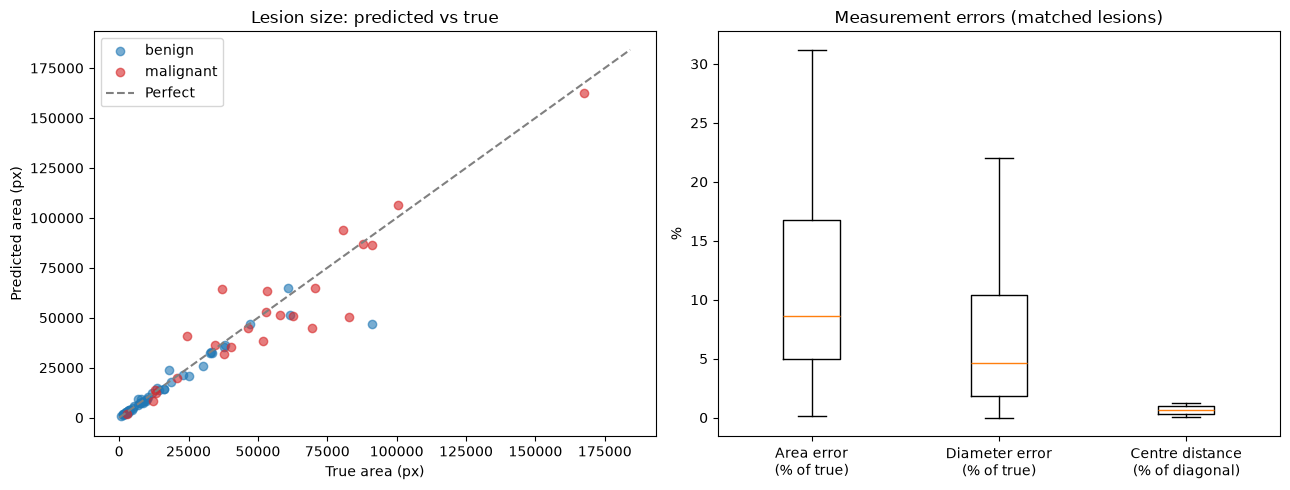

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: predicted vs true area (points on the dashed line = perfect)
for class_name, color in [('benign', 'tab:blue'), ('malignant', 'tab:red')]:
    part = matches[matches['label'] == class_name]
    axes[0].scatter(part['true_area_px'], part['pred_area_px'], alpha=0.6, color=color, label=class_name)
limit = max(matches['true_area_px'].max(), matches['pred_area_px'].max()) * 1.1
axes[0].plot([0, limit], [0, limit], color='grey', linestyle='--', label='Perfect')
axes[0].set_xlabel('True area (px)')
axes[0].set_ylabel('Predicted area (px)')
axes[0].set_title('Lesion size: predicted vs true')
axes[0].legend()

# Right: how far off the size and centre are
axes[1].boxplot([matches['area_error_pct'], matches['diameter_error_pct'], matches['centre_distance_pct']],
                tick_labels=['Area error\n(% of true)', 'Diameter error\n(% of true)', 'Centre distance\n(% of diagonal)'],
                showfliers=False)
axes[1].set_ylabel('%')
axes[1].set_title('Measurement errors (matched lesions)')

plt.tight_layout()
plt.savefig(MODEL_DIR / 'size_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Lesion report for one image

This is what the app will show for an uploaded scan: the predicted class (if the model has one), a numbered outline of every lesion and a table of measurements.

**Red** = predicted lesion with its number and box, **green** = true outline (only when the ground truth is known).

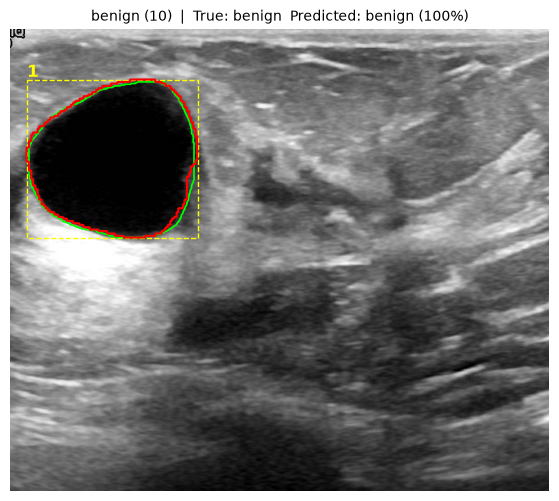

,lesion,area_px,area_pct,longest_diameter_px,centre_x,centre_y,depth_px,horizontal_zone,depth_zone,shape,orientation,circularity,solidity
0,1,32774,8.203,222.8,134.8,164.3,64,left,shallow,round,wider than tall,0.679,0.975


In [13]:
# Predicted class for each test image, if this model has a classification head
predictions_file = MODEL_DIR / 'test_predictions.csv'
class_predictions = pd.read_csv(predictions_file) if predictions_file.exists() else pd.DataFrame()
HAS_CLASSES = 'predicted' in class_predictions.columns


def prediction_text(image_path):
    """e.g. 'Predicted: benign (91%)', or '' if the model doesn't classify."""
    if not HAS_CLASSES:
        return ''
    row = class_predictions[class_predictions['image_path'] == image_path].iloc[0]
    return f"Predicted: {row['predicted']} ({row['prob_' + row['predicted']]:.0%})"


def draw_report(image_path, mask, true_mask=None, title=''):
    """Image with every lesion outlined, boxed and numbered. Returns the figure."""
    image = Image.open(DATA_DIR / image_path).convert('L')
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(image, cmap='gray')

    if true_mask is not None and true_mask.any():
        ax.contour(true_mask, levels=[0.5], colors='lime', linewidths=1.2)               # true outline

    for number, (region, lesion_mask) in enumerate(find_lesions(mask), start=1):
        top, left, bottom, right = region.bbox
        ax.contour(lesion_mask, levels=[0.5], colors='red', linewidths=1.5)              # predicted outline
        ax.add_patch(patches.Rectangle((left, top), right - left, bottom - top,
                                       fill=False, edgecolor='yellow', linestyle='--', linewidth=1))
        ax.text(left, top - 4, str(number), color='yellow', fontsize=12, fontweight='bold')   # lesion number

    ax.set_title(title, fontsize=10)
    ax.axis('off')
    return fig


# Example: a test image with a lesion
sample = test_df[test_df['label'] != 'normal'].iloc[0]
sample_mask = load_pred_mask(sample['image_path'])
title = f"{Path(sample['image_path']).stem}  |  True: {sample['label']}  {prediction_text(sample['image_path'])}"
draw_report(sample['image_path'], sample_mask, load_true_mask(sample['mask_paths']), title)
plt.show()

report_columns = ['lesion', 'area_px', 'area_pct', 'longest_diameter_px', 'centre_x', 'centre_y', 'depth_px',
                  'horizontal_zone', 'depth_zone', 'shape', 'orientation', 'circularity', 'solidity']
sample_lesions = measure_mask(sample_mask)
pd.DataFrame(sample_lesions)[report_columns] if sample_lesions else 'No lesion found'

## 8. Save an overlay for every test image (for the app)

In [14]:
for row in test_df.itertuples():
    mask = load_pred_mask(row.image_path)
    n_lesions = len(find_lesions(mask))
    title = (f'{Path(row.image_path).stem}  |  True: {row.label}  {prediction_text(row.image_path)}'
             f'  |  Lesions found: {n_lesions}')

    fig = draw_report(row.image_path, mask, load_true_mask(row.mask_paths), title)
    save_path = OVERLAY_DIR / row.image_path                  # e.g. overlays/benign/benign (12).png
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.close(fig)                                            # don't display, just save

print(f'Saved {len(test_df)} overlays to {OVERLAY_DIR}')

Saved 104 overlays to outputs/unet_multitask/overlays
